# ReCom parameter exploration (October 2022)

Exploratory analysis from while the flow-biased spanning tree was being developed. It compares ReCom chains on Wisconsin census block groups to choose settings for the later experiments:

- **Random vs. flow-biased spanning trees** at cut-edge compactness bounds of 1× and 5×
- **Random seed**: 500-step biased chains with seeds 2018, 1776, and 1993
- **Chain length**: how many steps capture the full range of values (1,000 turned out to be enough, so later experiments used 1,000-step chains)

Each plan is scored on three metrics. **"Modularity" in this notebook is the interaction ratio**, its earlier name: within-district mobility flows divided by between-district flows. The other two are Polsby–Popper compactness and efficiency gap.

Findings recorded below:
- Biasing the trees raised the interaction ratio at the 1× compactness bound, mostly by shifting the whole distribution up rather than extending its extremes. At 5× it lowered the interaction ratio on average.
- The seed made no substantial difference.
- Biasing did not change the range of efficiency gap values; the compactness bound did.

The chain outputs it reads were on the lab server and are not included, so this notebook is a record of the analysis and will not run as-is.

### Analyze experiment results to find ideal recom parameter settings

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import json
import plotly.express as px
import plotly.io as pio
import pandas
from copy import deepcopy
import geopandas as gpd
import numpy as np
import timeit
import sys, importlib, os
from matplotlib.cbook import boxplot_stats
import os

### This paper justifies a couple settings
    1. https://mggg.org/VA-report.pdf
    2. ReCom is seed independent (changes enough that it doesn't matter); Figure 8
    3. Could also compute cut edges for comapctness, since it seems better than other metrics for visual compactness
    4. 10,000 steps is enough for convergence for their ReCom settings
        - There aren't any theoretical guarantees regarding mixiting time for recom, but can use heuristic methods
        - Figure 9
          - Look at distribution of values for indexed districts at 2k steps, 10k steps, and 20k steps
              - see if 10k and 20k look similar
    5. We emphasize that these ensemble methods should not be used to select a plan for enactment because they are made without local and community-based considerations. Instead, ensemble methods give an effective means of verifying whether a newly proposed plan is an extreme outlier in the universe of valid plans

    

In [32]:
comp2018 = pd.read_csv('221017_500it_1comp_1bias_2018seed_wi_2020.csv').drop(columns=['Unnamed: 0'])
comp1776 = pd.read_csv('221017_500it_1comp_1bias_1776seed_wi_2020.csv').drop(columns=['Unnamed: 0'])
comp1993 = pd.read_csv('221017_500it_1comp_1bias_1993seed_wi_2020.csv').drop(columns=['Unnamed: 0'])

In [34]:
comp2018.describe().iloc[[1,2,3,7]]

,compactness,Eff_gap
mean,0.215191,-0.119408
std,0.019535,0.085942
min,0.168901,-0.324477
max,0.287705,0.043181


In [35]:
comp1776.describe().iloc[[1,2,3,7]]

,compactness,Eff_gap
mean,0.222451,-0.178864
std,0.016071,0.063898
min,0.185183,-0.230763
max,0.292173,0.028530


In [36]:
comp1993.describe().iloc[[1,2,3,7]]

,compactness,Eff_gap
mean,0.221524,-0.099662
std,0.018702,0.044338
min,0.186480,-0.228533
max,0.288078,0.020130


### Show heursitic evidence for convergence
    - https://mggg.org/VA-report.pdf

#### Plot helpers

In [37]:
def def_axes(ax00, ax01):
    ymin00, ymax00 = ax00.get_ylim()
    xmin00, xmax00 = ax00.get_xlim()
    ymin01, ymax01 = ax01.get_ylim()
    xmin01, xmax01 = ax01.get_xlim()
    xs = [xmin00, xmax00, xmin01, xmax01]
    ys = [ymin00, ymax00, ymin01, ymax01]
    xmin = min(xs)
    xmax = max(xs)
    ymin = min(ys)
    ymax = max(ys)
    
    ax00.set_xlim([xmin,xmax])
    ax00.set_ylim([ymin,ymax])
    ax01.set_xlim([xmin,xmax])
    ax01.set_ylim([ymin,ymax])
    ax00.legend()
    ax01.legend()

In [178]:
def annotate_boxplot(bpdict, annotate_params=None,
                     x_offset=0.05, number_bps=9,
                     text_offset_x=45,
                     text_offset_y=3):
    """Annotates a matplotlib boxplot with labels marking various centile levels.

    Parameters:
    - bpdict: The dict returned from the matplotlib `boxplot` function. If you're using pandas you can
    get this dict by setting `return_type='dict'` when calling `df.boxplot()`.
    - annotate_params: Extra parameters for the plt.annotate function. The default setting uses standard arrows
    and offsets the text based on other parameters passed to the function
    - x_offset: The offset from the centre of the boxplot to place the heads of the arrows, in x axis
    units (normally just 0-n for n boxplots). Values between around -0.15 and 0.15 seem to work well
    - x_loc: The x axis location of the boxplot to annotate. Usually just the number of the boxplot, counting
    from the left and starting at zero.
    text_offset_x: The x offset from the arrow head location to place the associated text, in 'figure points' units
    text_offset_y: The y offset from the arrow head location to place the associated text, in 'figure points' units
    """
    if annotate_params is None:
        annotate_params = dict(xytext=(text_offset_x, text_offset_y), textcoords='offset points', arrowprops={'arrowstyle':'->'})
    
    for i in range(number_bps):
#         plt.annotate('Median', (i + 1 + x_offset, bpdict['medians'][i].get_ydata()[0]), **annotate_params)
#         plt.annotate('25%', (i + 1 + x_offset, bpdict['boxes'][i].get_ydata()[0]), **annotate_params)
#         plt.annotate('75%', (i + 1 + x_offset, bpdict['boxes'][i].get_ydata()[2]), **annotate_params)
        val = bpdict['caps'][i*2].get_ydata()[0]
        plt.annotate(f'{val:.2f}', (i + 1 + x_offset, bpdict['caps'][i*2].get_ydata()[0]), **annotate_params)
        val = bpdict['caps'][(i*2)+1].get_ydata()[0]
        plt.annotate(f'{val:.2f}', (i + 1 + x_offset, bpdict['caps'][(i*2)+1].get_ydata()[0]), **annotate_params)


### Modularity Ratio
- sum of within-district flows / sum of between-district flows
- higher ratio means districts better capture communities
- https://matplotlib.org/stable/api/markers_api.html

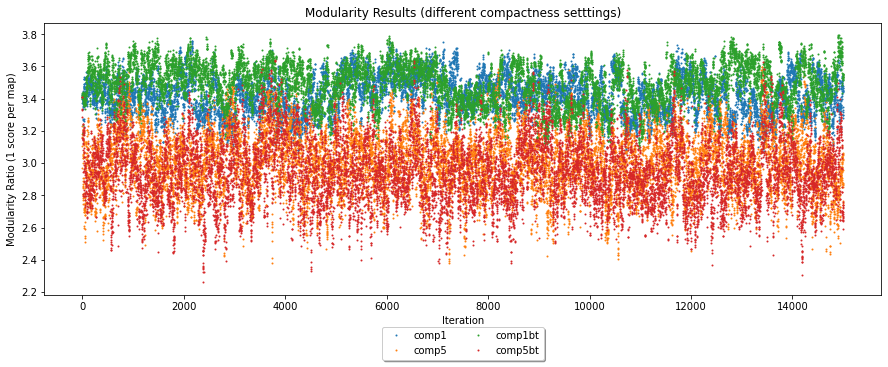

In [179]:
fig = plt.figure(figsize=(15,5)) # width, height
ax = plt.subplot(111)
###  1 comp
ax.plot(comp1.modularity, label='comp1', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5.modularity, label='comp5', marker='.',markersize = 2,linestyle='None')

ax.plot(comp1bt.modularity, label='comp1bt', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5bt.modularity, label='comp5bt', marker='.',markersize = 2,linestyle='None')


plt.title('Modularity Results (different compactness setttings)')
ax.set_xlabel('Iteration')
ax.set_ylabel('Modularity Ratio (1 score per map)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1),shadow=True, ncol=2)
plt.show()

https://blog.rtwilson.com/automatically-annotating-a-boxplot-in-matplotlib/

- label = tick label for the boxplot
- mean=arithmetic mean value
- med=50th percentile
- q1=first quartile (25th percentile)
- q3=third quartile (75th percentile)
- cilo=lower notch around the median
- cihi=upper notch around the median
- whislo=end of the lower whisker
- whishi=end of the upper whisker
- fliers=outliers

### Biasing the trees DID get higher modularity values fro compactness = 1
    - but moved up the trees on average more than improving the extremes
    - saw DECREASED modularity, on average, when compactness = 5
    - seed didn't make a substantial difference

Modularity values in 15000 iterations


Text(0.5, 1.0, 'Modularity (random trees): whiskers at 0 and 100%')

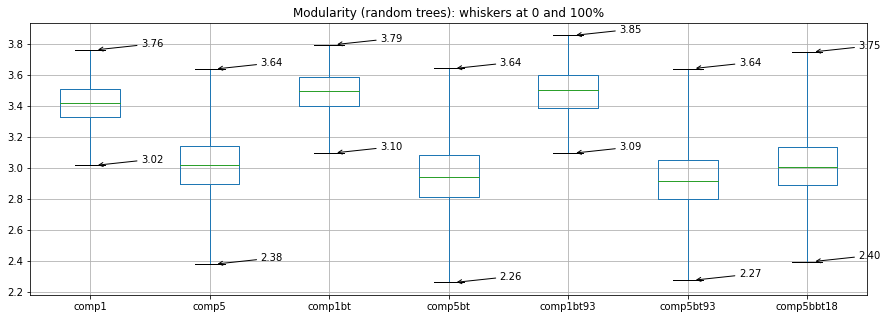

In [216]:
all_mods = [comp1.modularity,comp5.modularity,comp1bt.modularity,comp5bt.modularity,comp1bt93.modularity,comp5bt93.modularity,comp5bbt18.modularity]
labels = ['comp1', 'comp5','comp1bt', 'comp5bt','comp1bt93', 'comp5bt93', 'comp5bbt18']
stats = [boxplot_stats(i)[0] for i in all_mods]
df=pd.DataFrame.from_dict(stats)
df['labels']=labels
df.set_index(df.labels)

print('Modularity values in 15000 iterations') 
# print('Max modularity value = ',max(df.iloc[-1].fliers))
df = pd.DataFrame(all_mods).transpose()
df.columns = labels
df.describe()
bpdict = df.boxplot(whis=[0, 100], return_type='dict',figsize=(15,5))
annotate_boxplot(bpdict, number_bps=len(labels))
plt.title('Modularity (random trees): whiskers at 0 and 100%')

### Compactness
- https://github.com/mggg/GerryChain/blob/198f43dae397a7e361dcaa059a7ac8a4e0ff18f3/gerrychain/metrics/compactness.py
- gerrychain calculates Polsy-Popper for each partition, then our code computes the average values for each map

1. Polsby-popper is very senstive to complex boundary geometry (i.e. rugged shoreline)
    - should be ok because I simplified the shapefile for display in the webmap, but not for use in python

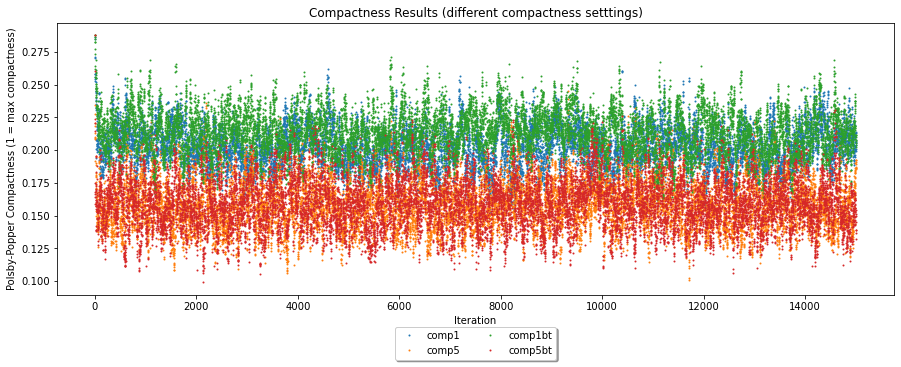

In [126]:
fig = plt.figure(figsize=(15,5)) # width, height
ax = plt.subplot(111)
###  1 comp
ax.plot(comp1.compactness, label='comp1', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5.compactness, label='comp5', marker='.',markersize = 2,linestyle='None')
ax.plot(comp1bt.compactness, label='comp1bt', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5bt.compactness, label='comp5bt', marker='.',markersize = 2,linestyle='None')

plt.title('Compactness Results (different compactness setttings)')
ax.set_xlabel('Iteration')
ax.set_ylabel('Polsby-Popper Compactness (1 = max compactness)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1),shadow=True, ncol=2)
plt.show()

Compactness values in 15000 iterations, compactness=1


Text(0.5, 1.0, 'Compactness (random trees): whiskers at 0 and 100%')

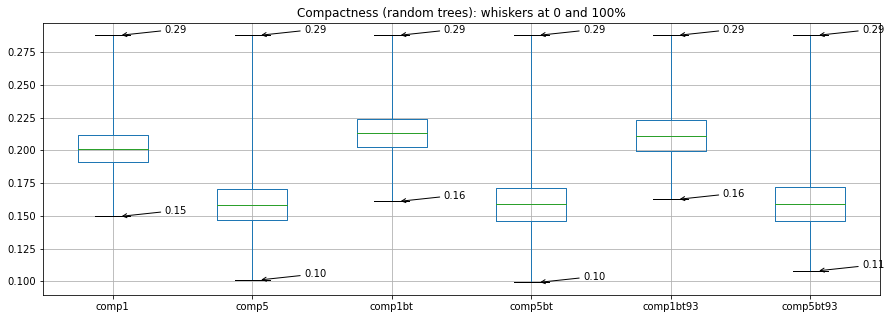

In [184]:
all_mods = [comp1.compactness,comp5.compactness,comp1bt.compactness,comp5bt.compactness,comp1bt93.compactness,comp5bt93.compactness]
labels = ['comp1','comp5','comp1bt','comp5bt','comp1bt93', 'comp5bt93']

print('Compactness values in 15000 iterations, compactness=1')
# print('Max modularity value = ',max(df.iloc[-1].fliers))
df = pd.DataFrame(all_mods).transpose()
df.columns = labels
df.describe()
bpdict = df.boxplot(whis=[0, 100], return_type='dict',figsize=(15,5))
annotate_boxplot(bpdict, number_bps=len(labels))
plt.title('Compactness (random trees): whiskers at 0 and 100%')

### Efficiency gap
- https://github.com/mggg/GerryChain/blob/198f43dae397a7e361dcaa059a7ac8a4e0ff18f3/gerrychain/metrics/partisan.py
- Uses wasted vote counts, not seats (the simplified version)
- Calculated with gerrychain with following method:

In [128]:
def efficiency_gap(results):
    """
    Computes the efficiency gap for the given ElectionResults.
    A positive value indicates an advantage for the first party listed
    in the Election's parties_to_columns dictionary.
    """
    party1, party2 = [results.counts(party) for party in results.election.parties]
    print(party1,party2)
    wasted_votes_by_part = map(wasted_votes, party1, party2)
    total_votes = results.total_votes()
    numerator = sum(waste2 - waste1 for waste1, waste2 in wasted_votes_by_part)
    return numerator / total_votes

I think I've confirmed that positive values are an advantage for Democrats, and negative values are an advantage for Republicans:
 - the results also generally favor Republicans (i.e. are negative), which makes sense with this

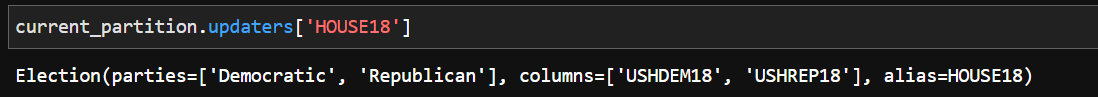

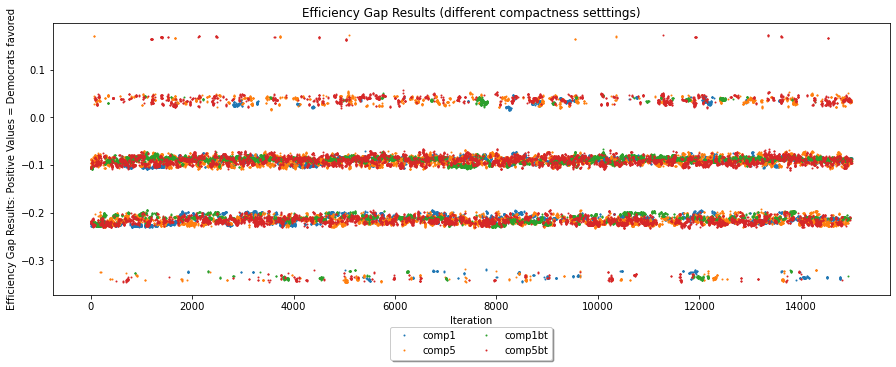

In [129]:
fig = plt.figure(figsize=(15,5)) # width, height
ax = plt.subplot(111)
###  1 comp
ax.plot(comp1.Eff_gap, label='comp1', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5.Eff_gap, label='comp5', marker='.',markersize = 2,linestyle='None')
ax.plot(comp1bt.Eff_gap, label='comp1bt', marker='.',markersize = 2,linestyle='None')
ax.plot(comp5bt.Eff_gap, label='comp5bt', marker='.',markersize = 2,linestyle='None')


plt.title('Efficiency Gap Results (different compactness setttings)')
ax.set_xlabel('Iteration')
ax.set_ylabel('Efficiency Gap Results: Positive Values = Democrats favored')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1),shadow=True, ncol=2)
plt.show()

### Biasing trees doesn't impact range (as expected)
    - but, compactness does

Efficiency Gap values in 15000 iterations, compactness=1


Text(0.5, 1.0, 'Efficiency Gap (random trees): whiskers at 0 and 100%')

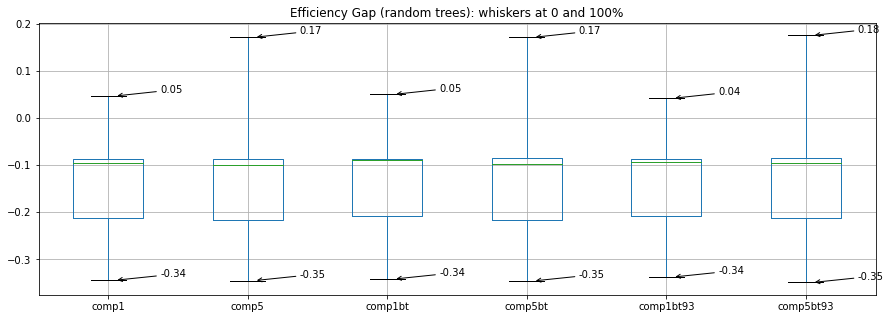

In [186]:
all_mods = [comp1.Eff_gap,comp5.Eff_gap,comp1bt.Eff_gap,comp5bt.Eff_gap,comp1bt93.Eff_gap,comp5bt93.Eff_gap]
labels = ['comp1','comp5','comp1bt','comp5bt','comp1bt93','comp5bt93']

print('Efficiency Gap values in 15000 iterations, compactness=1')
# print('Max modularity value = ',max(df.iloc[-1].fliers))
df = pd.DataFrame(all_mods).transpose()
df.columns = labels
df.describe()
bpdict = df.boxplot(whis=[0, 100], return_type='dict',figsize=(15,5))
annotate_boxplot(bpdict, number_bps=len(labels))
plt.title('Efficiency Gap (random trees): whiskers at 0 and 100%')